In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pairinteraction as pi

Omega = 0.51  # MHz, Rabi frequency (paper's measured value)
Z = 10.2      # µm, fixed trap separation
distances = np.linspace(0, 15, 100)  # µm

def compute_P2_and_B(Bfield_tesla, distances):
    ket = pi.KetAtom("Rb", n=79, l=2, j=2.5, m=0.5)  # single-atom target state |r>
    basis = pi.BasisAtom("Rb", n=(74, 84), l=(0, 4))
    system = pi.SystemAtom(basis)
    system.set_magnetic_field([0, 0, Bfield_tesla], unit="tesla")

    system.diagonalize()                      # do this for B = 0 too
    overlaps = system.get_eigenbasis().get_overlaps(ket)
    idx = np.argmax(overlaps)
    E_r = system.get_eigenenergies(unit="MHz")[idx]
    pair_energy = 2 * E_r
    min_energy, max_energy = pair_energy - 500, pair_energy + 500

    pair_basis = pi.BasisPair(
        [system, system], energy=(min_energy, max_energy), energy_unit="MHz"
    )

    pair_systems = [
        pi.SystemPair(pair_basis).set_distance_vector([0, d, Z], unit="micrometer")
        for d in distances
    ]
    pi.diagonalize(pair_systems, diagonalizer="eigen")

    P2_vals = []
    B_vals = []
    for s in pair_systems:
        delta_phi = s.get_eigenenergies(unit="MHz") - pair_energy      # Delta_phi
        kappa2 = s.get_eigenbasis().get_overlaps([ket, ket])            # |<phi|rr>|^2

        P2 = np.sum(Omega**2 * kappa2 / (Omega**2 + 2 * delta_phi**2))
        P2 = min(P2, 1.0)  # guard against tiny numerical overshoot
        B = Omega * np.sqrt((1 - P2) / (2 * P2)) if P2 > 0 else np.inf

        P2_vals.append(P2)
        B_vals.append(B)

    return np.array(P2_vals), np.array(B_vals)

A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets could not be found.
A bijective map between states and kets 

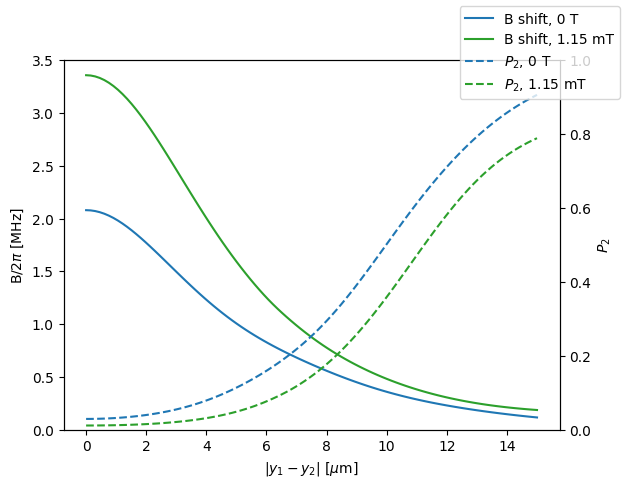

In [3]:
P2_0T, B_0T = compute_P2_and_B(0.0, distances)
P2_115mT, B_115mT = compute_P2_and_B(1.15e-3, distances)

fig, ax1 = plt.subplots()
ax1.plot(distances, B_0T, label="B shift, 0 T", color="tab:blue")
ax1.plot(distances, B_115mT, label="B shift, 1.15 mT", color="tab:green")
ax1.set_xlabel(r"$|y_1-y_2|$ [$\mu$m]")
ax1.set_ylabel(r"B/2$\pi$ [MHz]")
ax1.set_ylim(0, 3.5)

ax2 = ax1.twinx()
ax2.plot(distances, P2_0T, "--", label=r"$P_2$, 0 T", color="tab:blue")
ax2.plot(distances, P2_115mT, "--", label=r"$P_2$, 1.15 mT", color="tab:green")
ax2.set_ylabel(r"$P_2$")
ax2.set_ylim(0, 1)

fig.legend(loc="upper right")
plt.show()

In [9]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


blue, green = "#4da3ff", "#4cd964"   # brighter than tab:blue/green for dark bg

fig = make_subplots(specs=[[{"secondary_y": True}]])

# B shift (left axis, solid)
fig.add_trace(go.Scatter(x=distances, y=B_0T, name="B shift, 0 T",
                         line=dict(color=blue)), secondary_y=False)
fig.add_trace(go.Scatter(x=distances, y=B_115mT, name="B shift, 1.15 mT",
                         line=dict(color=green)), secondary_y=False)

# P2 (right axis, dashed)
fig.add_trace(go.Scatter(x=distances, y=P2_0T, name="P₂, 0 T",
                         line=dict(color=blue, dash="dash")), secondary_y=True)
fig.add_trace(go.Scatter(x=distances, y=P2_115mT, name="P₂, 1.15 mT",
                         line=dict(color=green, dash="dash")), secondary_y=True)

fig.update_xaxes(title_text="|y₁ − y₂| [µm]")
fig.update_yaxes(title_text="B/2π [MHz]", range=[0, 3.5], secondary_y=False)
fig.update_yaxes(title_text="P₂", range=[0, 1], secondary_y=True, showgrid=False)

fig.update_layout(
    template="plotly_dark",
    legend=dict(x=0.5, y=0.98, xanchor="center", yanchor="top"),
)
fig.show()

Fig5-like (ideal) | no control: {'a': np.float64(0.49295991040289144), 'f_MHz': np.float64(0.5131914967230381), 'tau_us': np.float64(523.4959001750163)} | with control: {'a': np.float64(0.037873429553673885), 'f_MHz': np.float64(0.24798747097734303), 'tau_us': np.float64(3.754951225986707)}
Fig6-like (SPAM) | no control: {'a': np.float64(0.4050818937612588), 'f_MHz': np.float64(0.5170602174471185), 'tau_us': np.float64(69.33563425090348)} | with control: {'a': np.float64(0.1595762277017393), 'f_MHz': np.float64(0.5388376529007104), 'tau_us': np.float64(1.9832644128254093)}


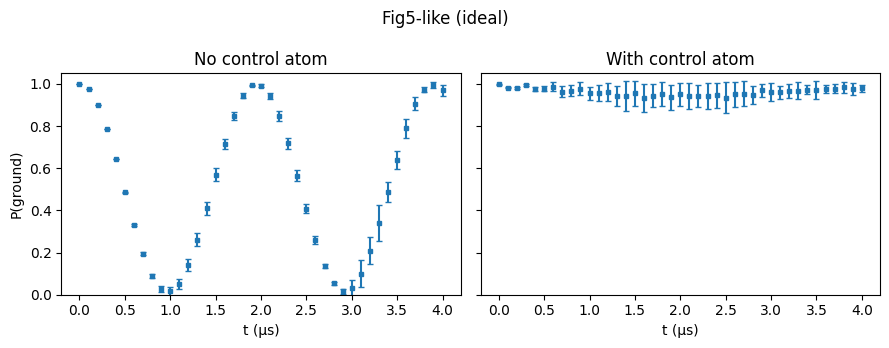

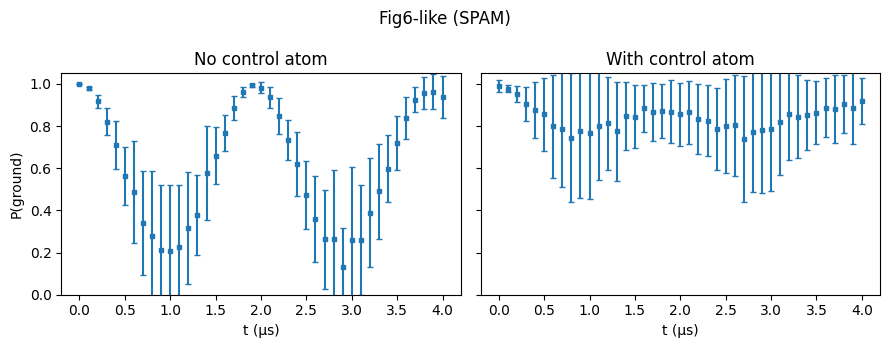

In [2]:
import numpy as np
from dataclasses import dataclass
from qutip import basis, qeye, tensor
from scipy.optimize import curve_fit

TWO_PI = 2 * np.pi
kB, amu = 1.380649e-23, 1.66053907e-27


@dataclass
class Params:
    # trap
    wf: float = 3.0            # trap waist (um)
    lam_f: float = 1.064       # trap wavelength (um)
    T: float = 180e-6          # atomic temperature (K)
    U0: float = 4.1e-3         # trap depth U0/kB (K)
    mass: float = 86.909 * amu # 87Rb
    # excitation beams (um)
    wx780: float = 11.9
    wz780: float = 7.0
    wx480: float = 11.3
    wz480: float = 9.0
    lam780: float = 0.780
    lam480: float = 0.480
    # laser / light-shift
    Omega0: float = TWO_PI * 0.51
    Delta0: float = 0.0
    b: float = 4.0
    # interaction, Gaussian fit of Delta_dd(yc - yt); n = 79 values
    Ddd0: float = TWO_PI * 3.14
    a_dd: float = TWO_PI * 0.11
    sig_dd: float = 4.3
    # SPAM parameters (set all to 1 for the ideal Fig. 5)
    eta_p: float = 1.0
    eta_Rd: float = 1.0


# ---------------------------------------------------------------- operators
g, r = basis(2, 0), basis(2, 1)
n = r * r.dag()
sx = g * r.dag() + r * g.dag()
I2 = qeye(2)
nc, nt = tensor(n, I2), tensor(I2, n)
sxc, sxt = tensor(sx, I2), tensor(I2, sx)


def H_pulse(Om_c, Om_t, D_c, D_t, Ddd):
    """Rotating-frame Hamiltonian (hbar = 1), real Rabi frequencies."""
    return (-D_c * nc - D_t * nt
            - 0.5 * Om_c * sxc - 0.5 * Om_t * sxt
            + Ddd * nc * nt)


# ---------------------------------------------------------- sampling pieces
class Sim:
    def __init__(self, p=Params(), seed=1):
        self.p = p
        self.rng = np.random.default_rng(seed)
        Trel = p.T / p.U0
        self.sig_xz = 0.5 * p.wf * np.sqrt(Trel)
        self.sig_y = np.pi * p.wf**2 / (np.sqrt(2) * p.lam_f) * np.sqrt(Trel)
        self.sig_v = np.sqrt(kB * p.T / p.mass)          # m/s == um/us
        self.dk = TWO_PI * (1 / p.lam780 - 1 / p.lam480)  # k1 - k2 (1/um)

    def envelope(self, x, y, z):
        """I(r)/I(0) = E780 * E480, Eq. (S2), exponent used exactly as written."""
        p, f = self.p, 1.0
        for wx, wz, lam in ((p.wx780, p.wz780, p.lam780),
                            (p.wx480, p.wz480, p.lam480)):
            Lx, Lz = np.pi * wx**2 / lam, np.pi * wz**2 / lam
            qx, qz = 1 + y**2 / Lx**2, 1 + y**2 / Lz**2
            f *= (qx * qz) ** -0.25 * np.exp(-x**2 / (wx**2 * qx)) \
                 * np.exp(-z**2 / (wz**2 * qz))
        return f

    def draw_atom(self):
        """Returns (Omega, Delta, y) for one atom in its own trap frame."""
        p, R = self.p, self.rng
        x, z = R.normal(0, self.sig_xz, 2)
        y = R.normal(0, self.sig_y)
        vy = R.normal(0, self.sig_v)
        Om = p.Omega0 * self.envelope(x, y, z)
        D = p.Delta0 + self.dk * vy + p.b * (Om - p.Omega0)
        return Om, D, y

    def Ddd(self, yc, yt):
        p = self.p
        return p.a_dd + (p.Ddd0 - p.a_dd) * np.exp(-(yc - yt)**2 / (2 * p.sig_dd**2))

    # ------------------------------------------------------- one realization
    def realization(self, t, with_control):
        p, R = self.p, self.rng
        Om_c, D_c, yc = self.draw_atom()
        Om_t, D_t, yt = self.draw_atom()
        t_pi = np.pi / p.Omega0

        if R.random() > p.eta_p:                 # target not optically pumped
            Pg = 1.0
        else:
            ctrl = with_control and (R.random() < p.eta_p)
            Ddd = self.Ddd(yc, yt) if ctrl else 0.0
            # D_c = 0 in the target pulse and D_t = 0 in the control pulse:
            # drops free-evolution phases, as the supplement does.
            Ut = (-1j * H_pulse(0, Om_t, 0, D_t, Ddd) * t).expm()
            if ctrl:
                Uc = (-1j * H_pulse(Om_c, 0, D_c, 0, Ddd) * t_pi).expm()
                M = Uc * Ut * Uc                  # Eq. (S1), right-to-left in time
            else:
                M = Ut
            Pg = abs(M[0, 0]) ** 2                # |a'_00|^2
        return Pg + (1 - p.eta_Rd) * (1 - Pg)     # photoionisation correction

    def curve(self, ts, with_control, N=100):
        mean, std = [], []
        for t in ts:
            s = np.array([self.realization(t, with_control) for _ in range(N)])
            mean.append(s.mean()); std.append(s.std(ddof=1))
        return np.array(mean), np.array(std)


# ------------------------------------------------------------------ fitting
def model(t, a, f, tau_inv):
    return (1 - a) + a * np.cos(TWO_PI * f * t) * np.exp(-t * tau_inv)


def fit(ts, y):
    popt, _ = curve_fit(model, ts, y, p0=[0.4, 0.5, 0.0],
                        bounds=([0, 0.2, 0], [1, 1.0, 5]))
    return dict(a=popt[0], f_MHz=popt[1], tau_us=np.inf if popt[2] < 1e-6 else 1 / popt[2])


if __name__ == "__main__":
    import matplotlib.pyplot as plt

    ts = np.linspace(0, 4, 41)
    for label, p in (("Fig5-like (ideal)", Params(Ddd0=TWO_PI*3.4, wf=1, T=60e-6, U0=1e-3)),
                     ("Fig6-like (SPAM)", Params(eta_p=0.9, eta_Rd=0.95))):
        sim = Sim(p)
        free, e0 = sim.curve(ts, with_control=False)
        blk, e1 = sim.curve(ts, with_control=True)
        print(label, "| no control:", fit(ts, free), "| with control:", fit(ts, blk))

        fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
        for a_, y, e, ttl in ((ax[0], free, e0, "No control atom"),
                              (ax[1], blk, e1, "With control atom")):
            a_.errorbar(ts, y, e, fmt="s", ms=3, capsize=2)
            a_.set_title(ttl); a_.set_xlabel("t (µs)"); a_.set_ylim(0, 1.05)
        ax[0].set_ylabel("P(ground)")
        fig.suptitle(label); fig.tight_layout()

In [12]:
if __name__ == "__main__":
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

    ts = np.linspace(0, 4, 41)
    for label, p in (("Fig5-like (ideal)", Params()),
                     ("Fig6-like (SPAM)", Params(eta_p=0.9, eta_Rd=0.95))):
        sim = Sim(p)
        free, e0 = sim.curve(ts, with_control=False)
        blk, e1 = sim.curve(ts, with_control=True)
        print(label, "| no control:", fit(ts, free), "| with control:", fit(ts, blk))

        fig = make_subplots(
            rows=1, cols=2, shared_yaxes=True,
            subplot_titles=("No control atom", "With control atom"),
            horizontal_spacing=0.05,
        )
        for col, (y, e) in enumerate(((free, e0), (blk, e1)), start=1):
            fig.add_trace(
                go.Scatter(
                    x=ts, y=y, mode="markers",
                    marker=dict(symbol="square", size=5),
                    error_y=dict(type="data", array=e, visible=True,
                                 thickness=1, width=3),
                    showlegend=False,
                ),
                row=1, col=col,
            )
            fig.update_xaxes(title_text="t (µs)", row=1, col=col)

        fig.update_yaxes(range=[0, 1.05])
        fig.update_yaxes(title_text="P(ground)", row=1, col=1)
        fig.update_layout(
            title=dict(text=label, x=0.5),
            width=900, height=350,
            margin=dict(t=70, b=50, l=60, r=20),
            template="plotly_dark",
        )
        fig.show()

Fig5-like (ideal) | no control: {'a': np.float64(0.4816053752183821), 'f_MHz': np.float64(0.5174080989164782), 'tau_us': np.float64(66.18115889324346)} | with control: {'a': np.float64(0.16449153456776272), 'f_MHz': np.float64(0.32142406046319655), 'tau_us': np.float64(0.466398486114761)}


Fig6-like (SPAM) | no control: {'a': np.float64(0.4050818937612588), 'f_MHz': np.float64(0.5170602174471185), 'tau_us': np.float64(69.33563425090348)} | with control: {'a': np.float64(0.1595762277017393), 'f_MHz': np.float64(0.5388376529007104), 'tau_us': np.float64(1.9832644128254093)}
